# EXP04 — Tác động của Data Augmentation

So sánh baseline CNN với cùng cấu hình huấn luyện, chỉ khác augmentation áp dụng trên tập train. Validation giữ nguyên để phép so sánh không bị ảnh hưởng bởi biến đổi ngẫu nhiên.

In [19]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "train.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "train.py").is_file():
    raise FileNotFoundError("Mở notebook từ thư mục BTL02 hoặc thư mục notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from evaluate import evaluate_checkpoint
from train import run_experiment, select_device
from visualize import display_saved_figures

CONFIGS = {
    "Không augmentation": PROJECT_ROOT / "configs/exp04_no_augmentation.yaml",
    "Có augmentation": PROJECT_ROOT / "configs/exp04_data_augmentation.yaml",
}
configs = {name: yaml.safe_load(path.read_text(encoding="utf-8")) for name, path in CONFIGS.items()}
display(pd.DataFrame(configs).T)

,experiment,model,data_dir,output_dir,result_group,tensorboard_dir,epochs,batch_size,learning_rate,seed,device,augmentation
Không augmentation,EXP004_Data_Augmentation,baseline,data,results,EXP04/no_augmentation,runs,30,64,0.001,42,cuda,NaN
Có augmentation,EXP004_Data_Augmentation,baseline,data,results,EXP04/data_augmentation,runs,30,64,0.001,42,cuda,"{'rotation_degrees': 15, 'translate': ['0.05',..."


## Kiểm soát biến số

Hai lượt dùng chung kiến trúc baseline, split 80/20, seed, batch size, Adam, learning rate và số epoch. Khác biệt duy nhất là các phép biến đổi ngẫu nhiên trong config augmentation.

In [20]:
shared_keys = ("model", "data_dir", "epochs", "batch_size", "learning_rate", "seed", "device")
control, augmented = configs["Không augmentation"], configs["Có augmentation"]
for key in shared_keys:
    if control[key] != augmented[key]:
        raise ValueError(f"Hai cấu hình khác nhau ở biến kiểm soát {key!r}.")
if control.get("augmentation") or not augmented.get("augmentation"):
    raise ValueError("Cấu hình control phải tắt augmentation và cấu hình còn lại phải bật.")
print("Các biến kiểm soát khớp nhau; chỉ augmentation được thay đổi.")
print("Augmentation:", augmented["augmentation"])

Các biến kiểm soát khớp nhau; chỉ augmentation được thay đổi.
Augmentation: {'rotation_degrees': 15, 'translate': [0.05, 0.05], 'horizontal_flip_probability': 0.5}


## Dùng lại kết quả đã lưu

`RUN_DIRS` trỏ đến các lượt đã hoàn tất. Đặt giá trị của một cấu hình thành `None` khi muốn huấn luyện lại.

In [21]:
RUN_DIRS = {
    "Không augmentation": "results/EXP04/no_augmentation/baseline/20261126_085136_901148",
    "Có augmentation": "results/EXP04/data_augmentation/baseline/20261126_085317_007233",
}
runs = {}
for name, config_path in CONFIGS.items():
    run_path = RUN_DIRS[name]
    if run_path is None:
        runs[name] = run_experiment(config_path)
    else:
        run_path = Path(run_path)
        runs[name] = run_path if run_path.is_absolute() else PROJECT_ROOT / run_path
        if not (runs[name] / "best.pth").is_file():
            raise FileNotFoundError(f"Không tìm thấy checkpoint: {runs[name] / 'best.pth'}")
    print(f"{name}: {runs[name].relative_to(PROJECT_ROOT)}")

D:\DeepLearning_Group\BTL02\results\EXP04\no_augmentation\baseline\20261126_085136_901148 cuda {'input': [64, 1, 48, 48], 'output': [64, 7], 'loss': 1.9359233379364014, 'finite_gradients': True}
01/30  train 1.7158 30.50%  val 1.5938 38.59%
02/30  train 1.5236 41.42%  val 1.4708 43.47%
03/30  train 1.4145 45.96%  val 1.3737 47.49%
04/30  train 1.3205 49.52%  val 1.3173 50.52%
05/30  train 1.2347 53.18%  val 1.2646 52.32%
06/30  train 1.1613 56.02%  val 1.2311 52.80%
07/30  train 1.0928 58.89%  val 1.2076 54.60%
08/30  train 1.0204 62.08%  val 1.2117 54.88%
09/30  train 0.9457 64.85%  val 1.2272 55.63%
10/30  train 0.8847 67.30%  val 1.2576 55.69%
11/30  train 0.8129 70.07%  val 1.2747 55.36%
12/30  train 0.7421 73.17%  val 1.3051 55.61%
13/30  train 0.6747 75.67%  val 1.3821 55.31%
14/30  train 0.6018 78.43%  val 1.4534 54.39%
15/30  train 0.5437 80.35%  val 1.5766 54.48%
16/30  train 0.4824 82.68%  val 1.6198 54.13%
17/30  train 0.4205 85.01%  val 1.7557 53.36%
18/30  train 0.3621 87.

## Đánh giá trên validation

Checkpoint tốt nhất theo validation loss được đánh giá cùng trên validation set không augmentation. Macro F1 giúp quan sát hiệu quả trên các lớp cảm xúc ngoài accuracy tổng thể.

In [22]:
evaluations = {}
rows = []
for name, run in runs.items():
    config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
    training = json.loads((run / "training.json").read_text(encoding="utf-8"))
    evaluation_path = run / "evaluation.json"
    saved = json.loads(evaluation_path.read_text(encoding="utf-8")) if evaluation_path.is_file() else None
    if saved is None or saved.get("split") != "validation":
        saved = evaluate_checkpoint(
            run,
            PROJECT_ROOT / config["data_dir"],
            config["batch_size"],
            select_device(config["device"]),
            split="validation",
        )
    evaluations[name] = saved
    rows.append({
        "Thí nghiệm": name,
        "Best epoch": training["best_epoch"],
        "Best validation loss": training["best_val_loss"],
        "Validation accuracy": evaluations[name]["accuracy"],
        "Macro F1": evaluations[name]["macro_f1"],
        "Thời gian train (giây)": training["training_seconds"],
    })
results = pd.DataFrame(rows).set_index("Thí nghiệm")
display(results)

,Best epoch,Best validation loss,Validation accuracy,Macro F1,Thời gian train (giây)
Thí nghiệm,,,,,
Không augmentation,7,1.207596,0.545977,0.482315,92.880132
Có augmentation,30,1.080258,0.597005,0.546142,544.425192


## Learning curves

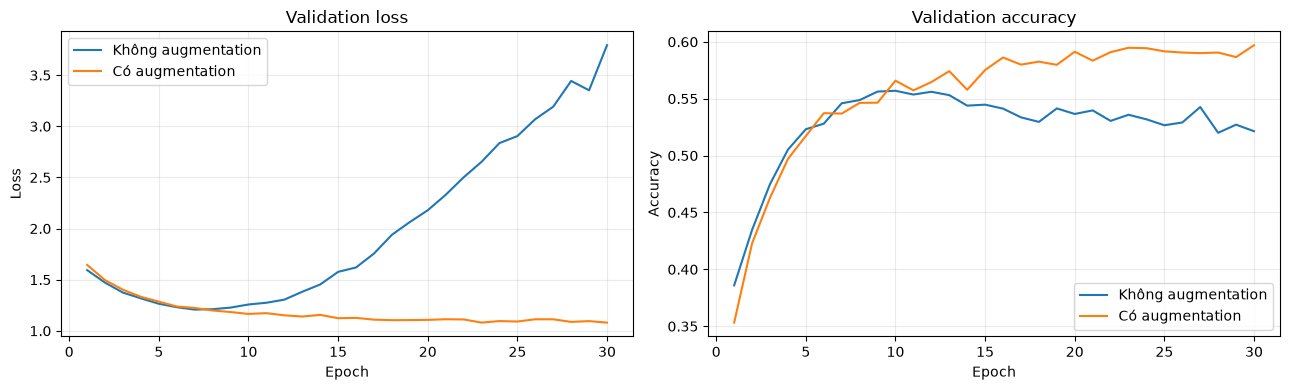

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, run in runs.items():
    history = pd.read_csv(run / "history.csv")
    axes[0].plot(history["epoch"], history["val_loss"], label=name)
    axes[1].plot(history["epoch"], history["val_accuracy"], label=name)
axes[0].set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()

## Ảnh đã lưu của từng lượt chạy

### Không augmentation

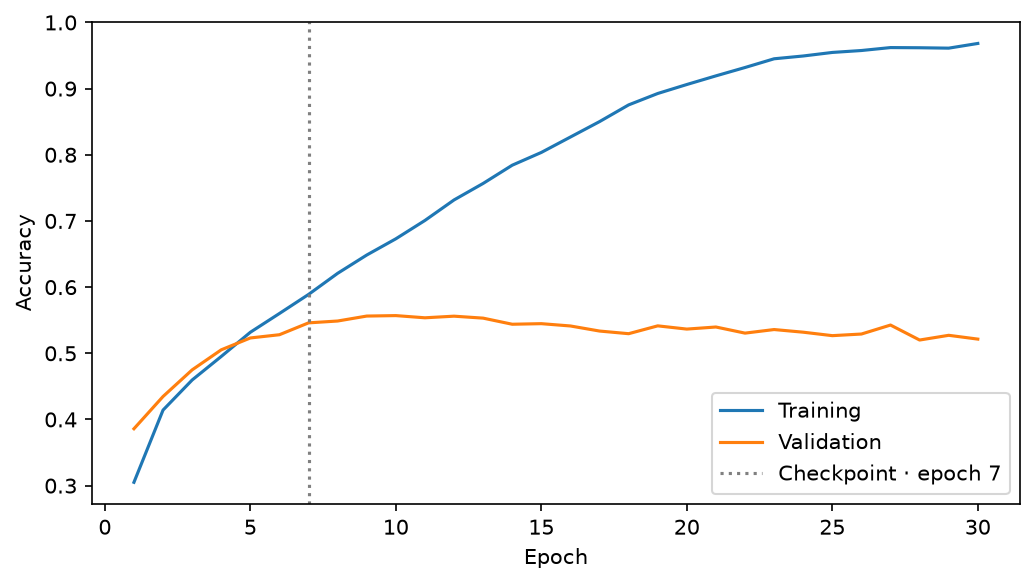

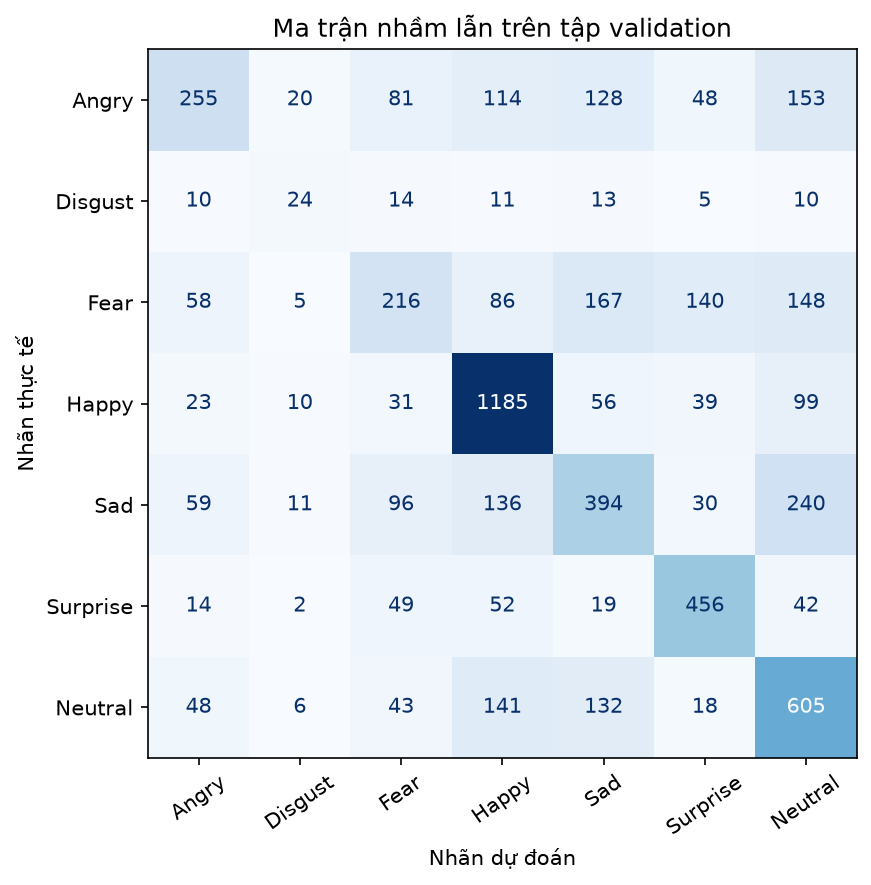

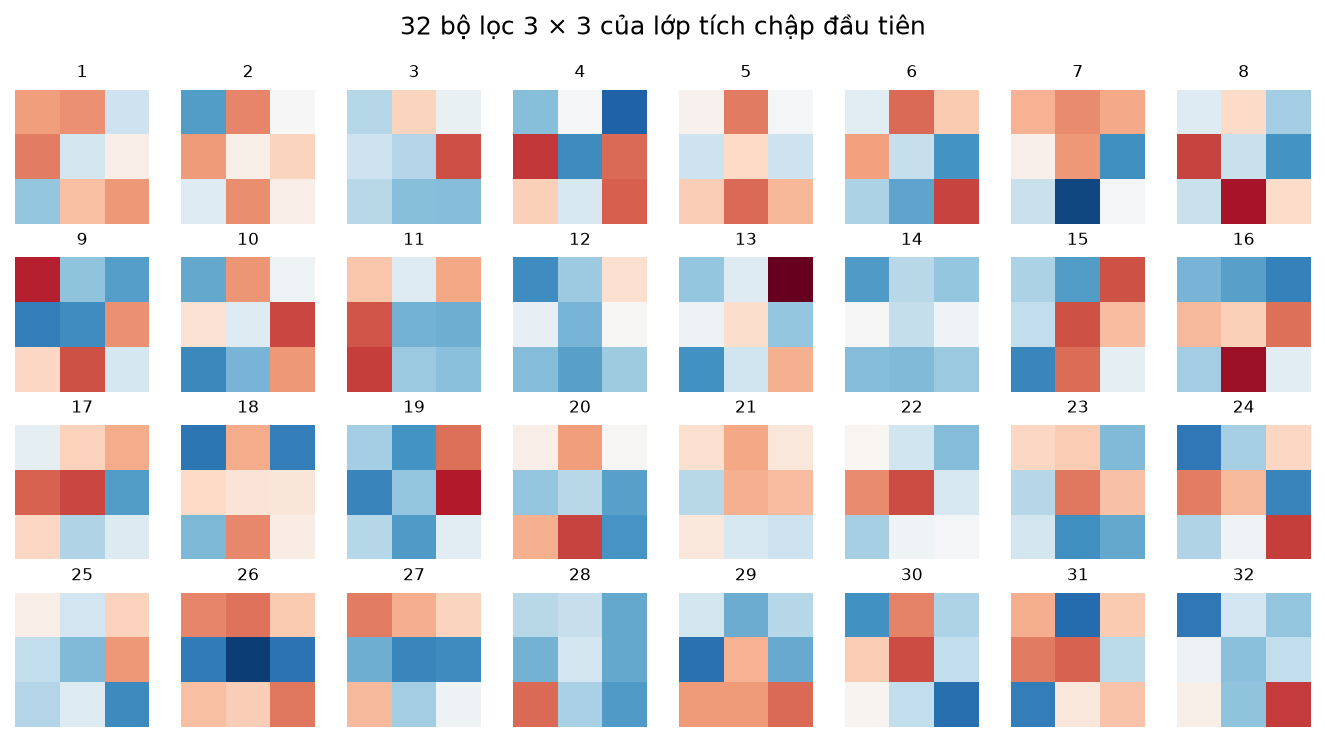

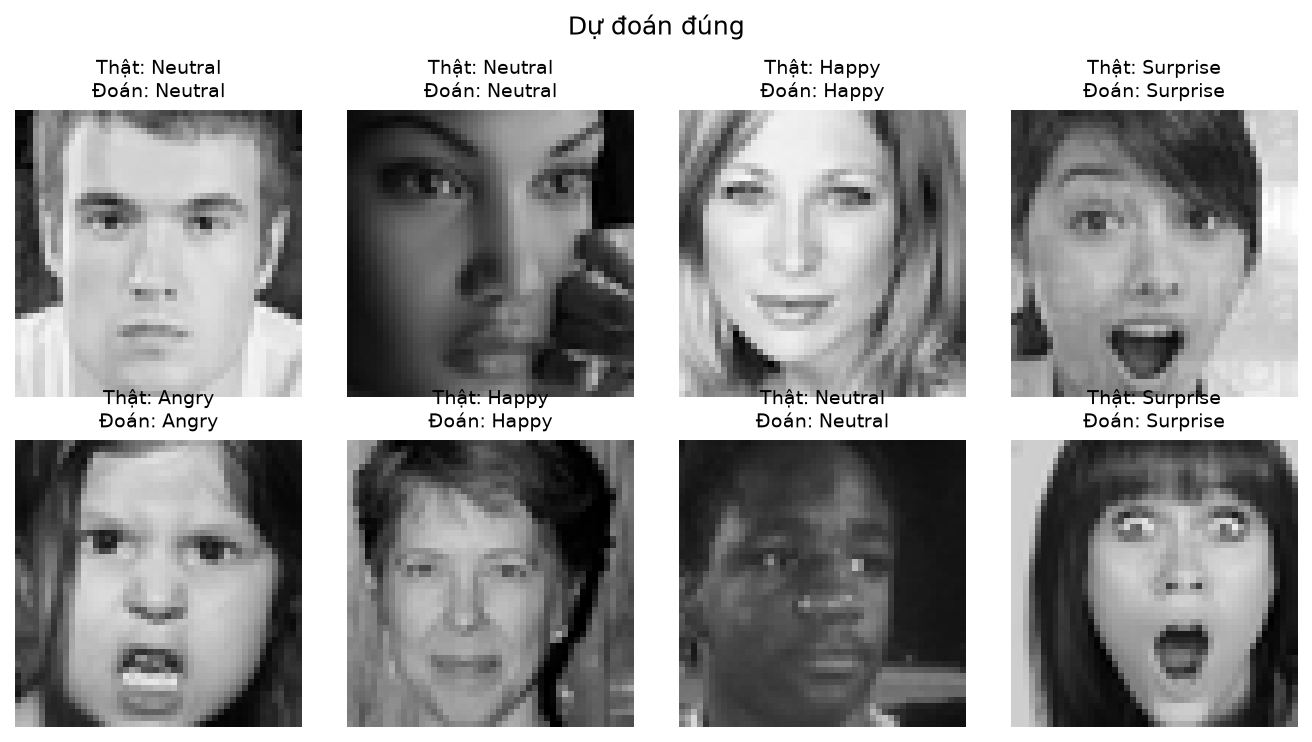

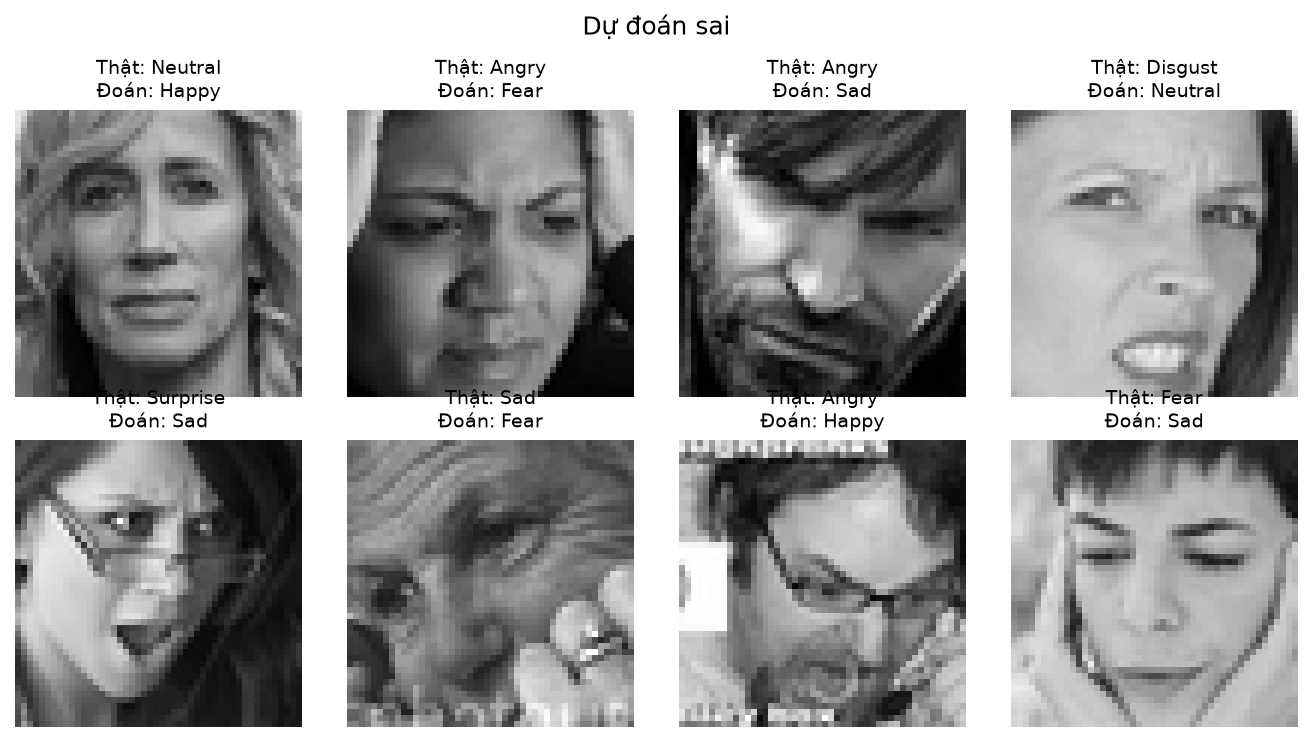

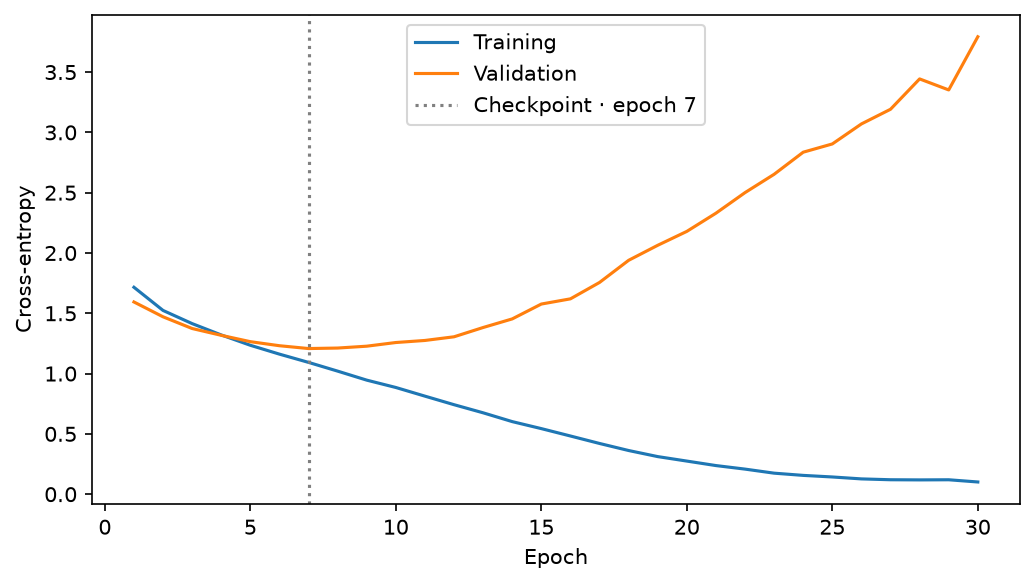

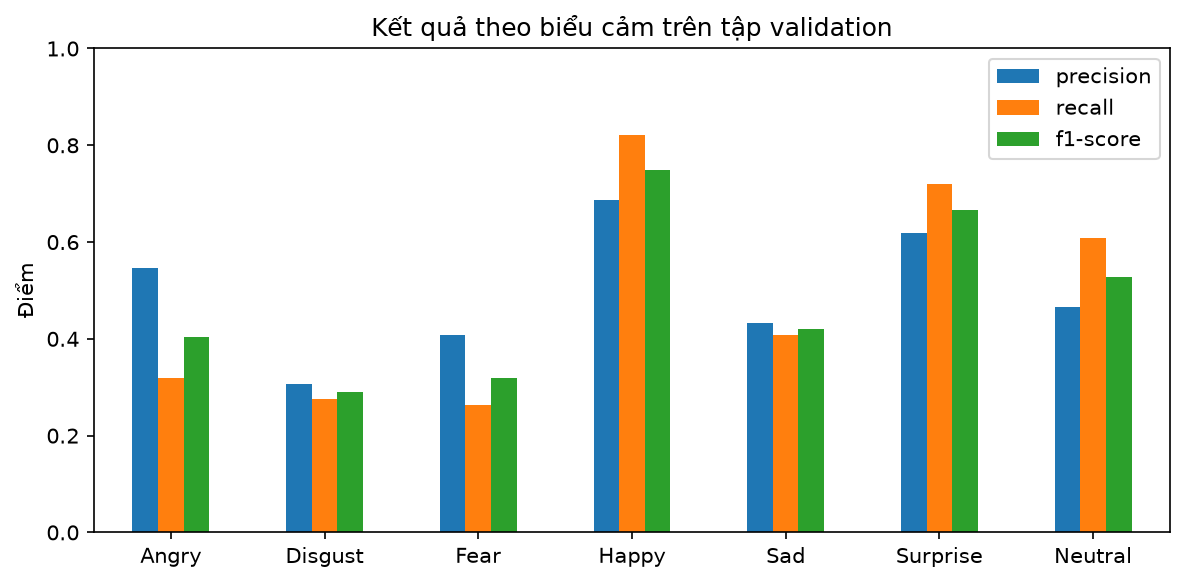

### Có augmentation

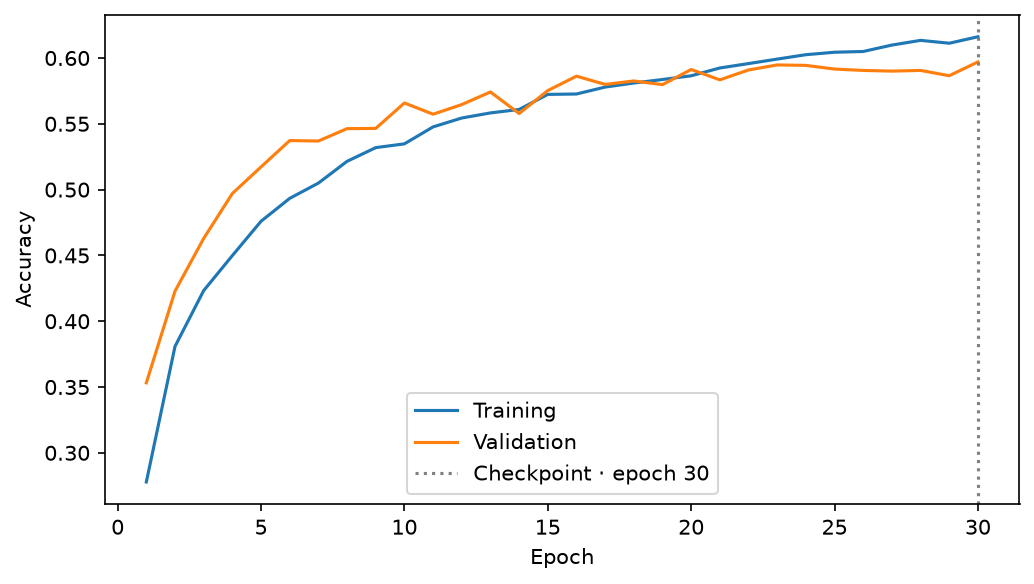

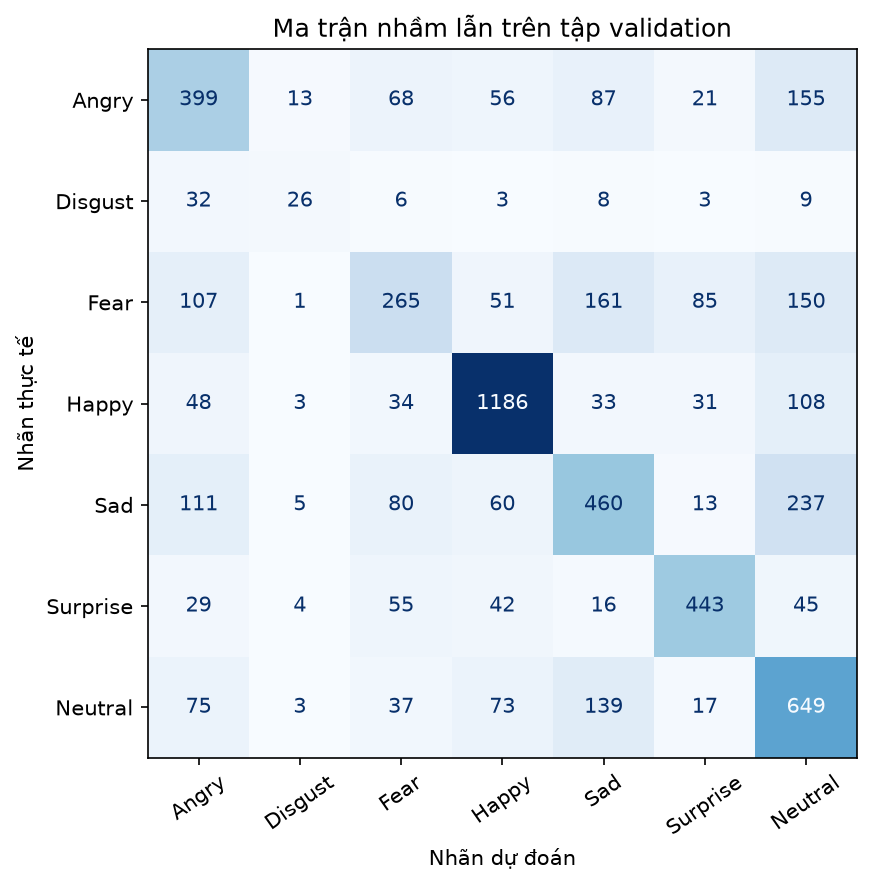

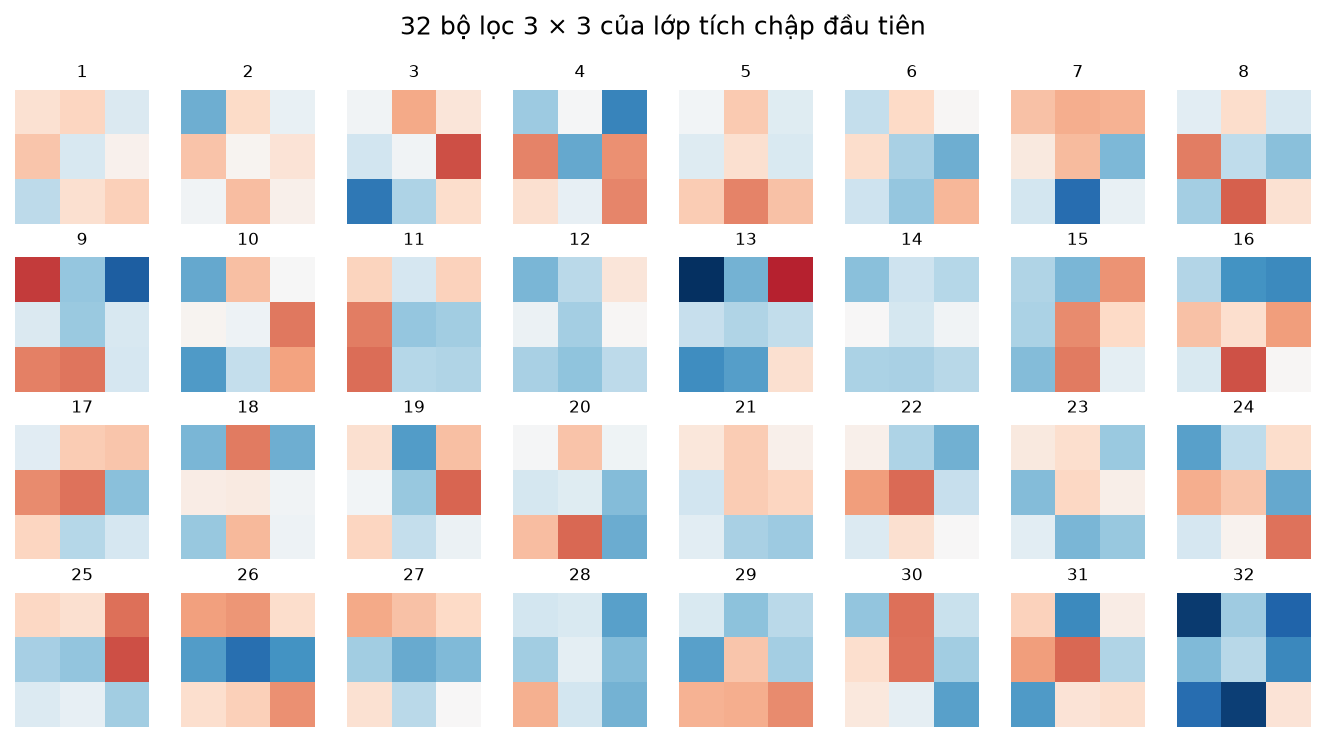

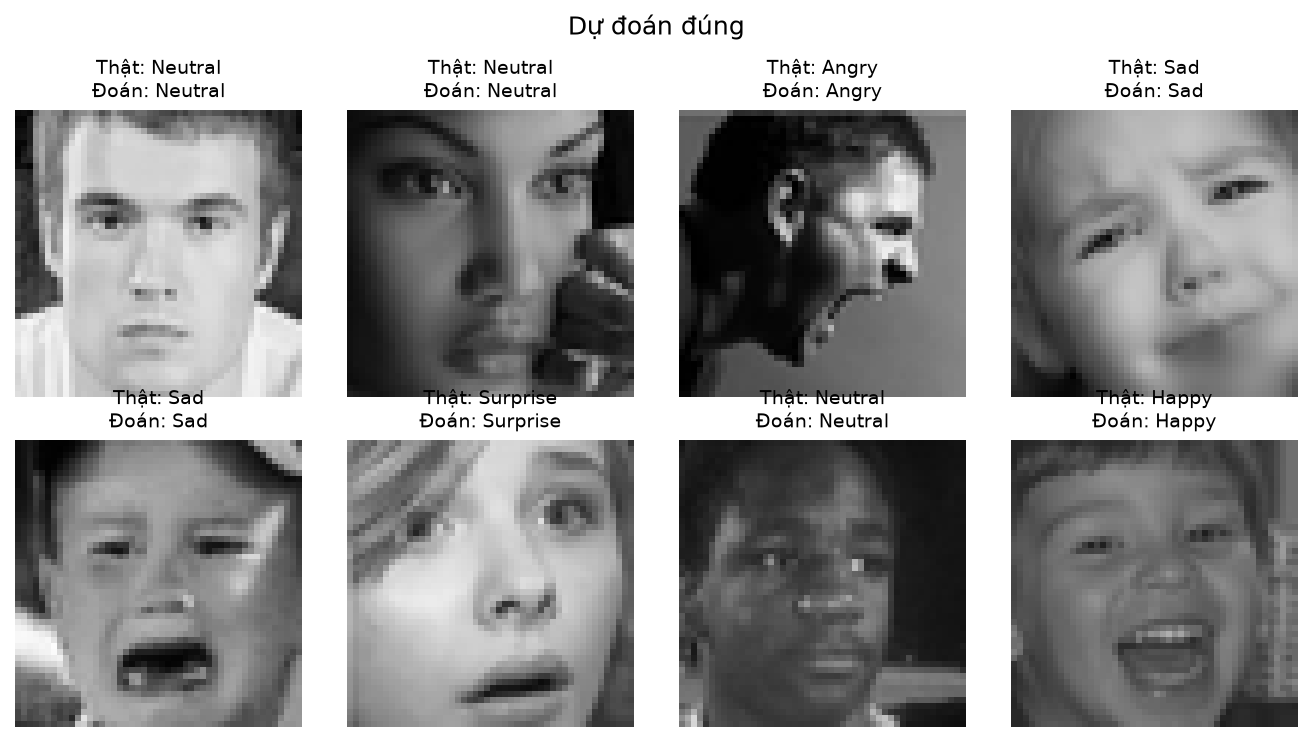

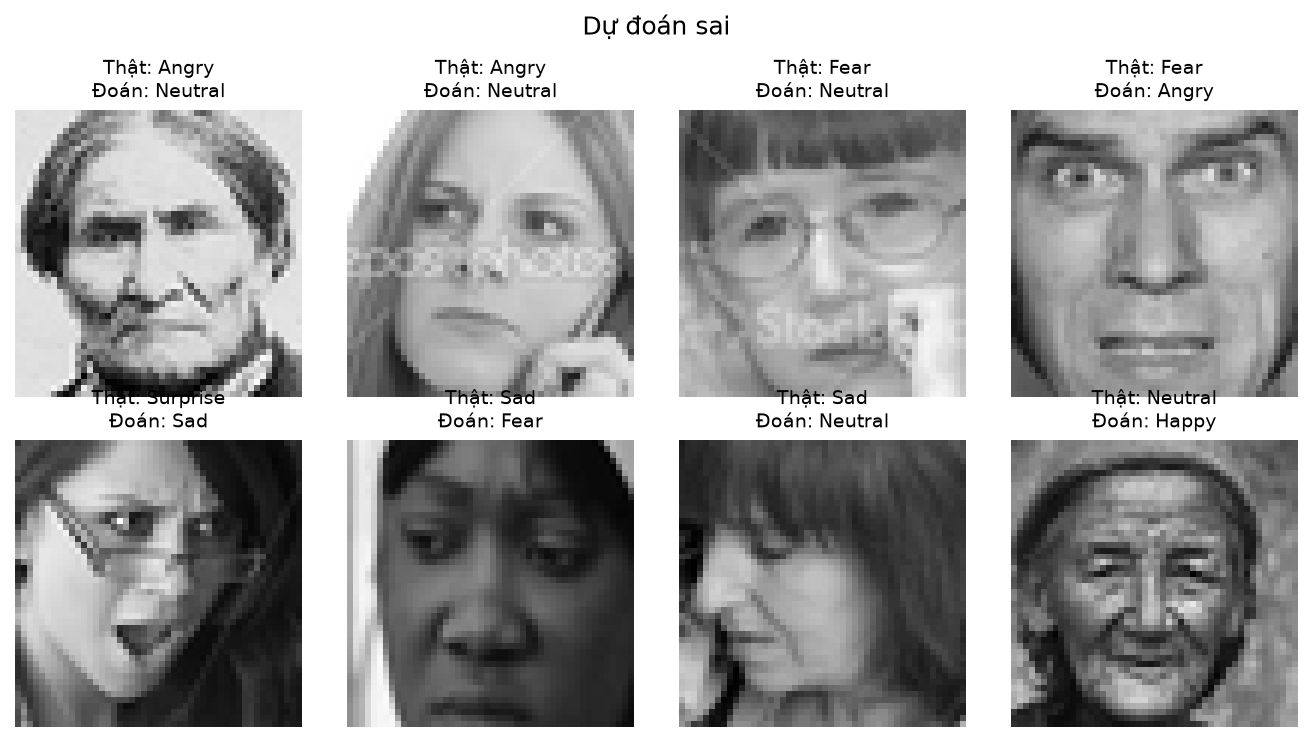

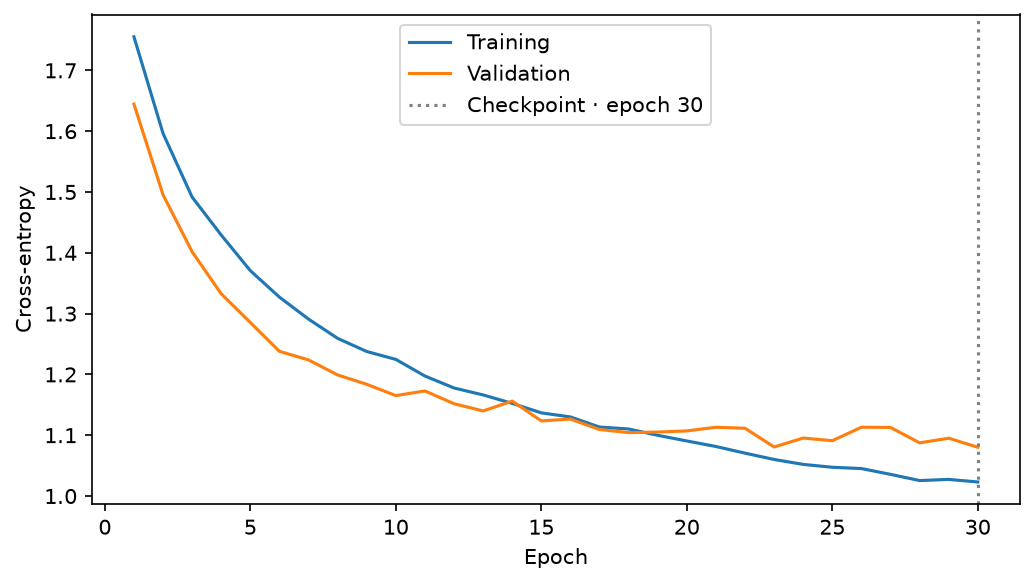

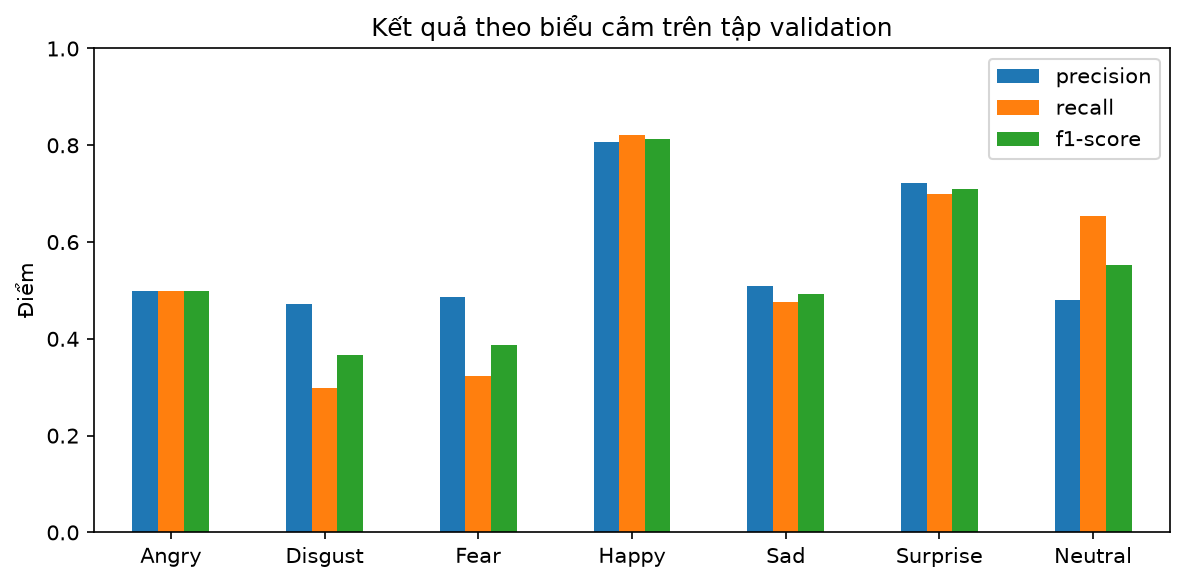

In [24]:
for name, run in runs.items():
    display(Markdown(f"### {name}"))
    display_saved_figures(run, width=650)

## Nhận xét

Dựa trên bảng và learning curves, so sánh validation accuracy, macro F1 và độ ổn định giữa hai lượt. Augmentation chỉ có ích nếu cải thiện khả năng tổng quát hóa trên validation mà không làm suy giảm đáng kể các lớp cụ thể; không kết luận từ training accuracy đơn lẻ. Ghi nhận kết quả quan sát được sau khi chạy notebook.